# Lab04. Сравниваем zero-shot, few-shot и LoRA

Берём первые 1000 отзывов test в исходном порядке. Во всех режимах используется та же Qwen3-0.6B, один системный запрос, жадная генерация и максимум три новых токена. Few-shot получает пять фиксированных примеров из validation; LoRA получает только отзыв и ранее обученный адаптер.

Все вычисления модели выполняются на облачной GPU Colab. Нового обучения здесь нет. Выберите T4 GPU, выполните ячейки по порядку и загрузите `lab04-colab-evaluation-inputs.zip`, когда появится кнопка выбора файла. Архив содержит наш код и адаптер, без базовых весов и исходного набора отзывов.

Сравнение с прежним локальным прогоном не подменяет этот эксперимент: здесь заново оцениваем все три режима в одной среде FP16. Результаты появляются только после фактического выполнения.

## 1. Проверяем облачную GPU

In [4]:
import os
from pathlib import Path
if not os.environ.get("COLAB_RELEASE_TAG") or not Path("/content").is_dir():
    raise RuntimeError("Этот ноутбук запускается только в облачном Google Colab")
import torch
if not torch.cuda.is_available():
    raise RuntimeError("Выберите GPU в настройках Colab")
print("Облачный GPU:", torch.cuda.get_device_name(0))
print("Память GPU, ГБ:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))

Облачный GPU: Tesla T4
Память GPU, ГБ: 15.64


## 2. Устанавливаем те же библиотеки, что при обучении

In [5]:
import subprocess, sys
REQUIREMENTS = ['transformers==4.57.1', 'peft==0.17.1', 'datasets==4.3.0', 'accelerate==1.11.0', 'safetensors==0.6.2', 'matplotlib==3.10.7']
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *REQUIREMENTS], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'transformers==4.57.1', 'peft==0.17.1', 'datasets==4.3.0', 'accelerate==1.11.0', 'safetensors==0.6.2', 'matplotlib==3.10.7'], returncode=0)

## 3. Загружаем сохранённый адаптер и код

Проверка SHA256 подтвердит, что это именно обученные ранее веса. После отключения старой облачной машины восстанавливаем их из локальной копии.

In [6]:
from google.colab import files
INPUT_ZIP = Path("/content/lab04-colab-evaluation-inputs.zip")
if not INPUT_ZIP.exists():
    uploaded = files.upload()
    if INPUT_ZIP.name not in uploaded:
        raise RuntimeError("Нужен файл lab04-colab-evaluation-inputs.zip")
    INPUT_ZIP.write_bytes(uploaded[INPUT_ZIP.name])
    del uploaded
print("Архив загружен, байт:", INPUT_ZIP.stat().st_size)

Архив загружен, байт: 18717303


In [7]:
import hashlib, json, zipfile
assert hashlib.sha256(INPUT_ZIP.read_bytes()).hexdigest() == '4c7317cbc39ca4ce1d4dded2cd2515ae8839ee5f115a366e7bb96db3c5809ada', "Архив изменился"
WORK = Path("/content/mtusi-lab04-evaluation")
WORK.mkdir(exist_ok=True)
ALLOWED = ['lab04/run.py', 'lab04/data.py', 'lab04/prompting.py', 'lab04/evaluation.py', 'lab04/artifacts/train_config.json', 'lab04/artifacts/adapter/adapter_config.json', 'lab04/artifacts/adapter/adapter_model.safetensors']
with zipfile.ZipFile(INPUT_ZIP) as z:
    assert sorted(z.namelist()) == sorted(ALLOWED)
    assert z.testzip() is None
    for name in ALLOWED:
        path = WORK / name
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(z.read(name))
train_config = json.loads((WORK / "lab04/artifacts/train_config.json").read_text())
weights = WORK / "lab04/artifacts/adapter/adapter_model.safetensors"
assert hashlib.sha256(weights.read_bytes()).hexdigest() == train_config["adapter_sha256"]
assert train_config["steps"] == 625 and train_config["training_status"] == "completed"
print("Адаптер проверен:", train_config["adapter_sha256"])
print("Обучение:", train_config["train_examples"], "отзывов;", train_config["steps"], "обновлений")

Адаптер проверен: afa22a5936230a18c245298ca8fa497f3675debc051e6013ff786624f1d7cbb0
Обучение: 5000 отзывов; 625 обновлений


## 4. Получаем 3000 ответов

Каждый режим отвечает на одни и те же 1000 отзывов. Правильная оценка не попадает в запрос. Она нужна только для сравнения уже полученного ответа. Контрольные суммы проверяют тестовую выборку и пять примеров few-shot. Длинные отзывы при проверке не обрезаются.

Код выводит прогресс каждые 100 отзывов. Время на ответ включает подготовку запроса, токенизацию, генерацию и разбор ответа; загрузка модели и один прогрев для каждого режима исключены. На каждом запросе синхронизируем GPU. Запросы обрабатываются по одному, без общего кеша между отзывами. Веса не обновляются.

In [8]:
OUT = WORK / "lab04/artifacts/evaluation"
env = os.environ.copy()
env["HF_HOME"] = "/content/huggingface-cache"
command = [sys.executable, "-u", str(WORK / "lab04/run.py"),
           "--device", "cuda", "--dtype", "float16", "--artifacts", str(OUT)]
process = subprocess.Popen(command, cwd=WORK, env=env, stdout=subprocess.PIPE,
                           stderr=subprocess.STDOUT, text=True, bufsize=1)
for line in process.stdout:
    print(line, end="", flush=True)
if process.wait() != 0:
    raise RuntimeError("Прогон прерван: смотрите ошибку выше")

I0000 00:00:1794304976.243285    3559 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794304978.852445    3559 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

Generating train split: 100%|██████████| 50000/50000 [00:00<00:00, 268380.49 examples/s]

Generating validation split: 100%|██████████| 5000/5000 [00:00<00:00, 246294.92 examples/s]

Generating test split: 100%|██████████| 2048/2048 [00:00<00:00, 202937.41 examples/s]
Отзывов: 1000, классы: {'1': 191, '2': 196, '3': 193, '4': 214, '5': 206}
SHA256 теста: 874107c454a1f0c9f0b9313359304291de9325d16478f83883f19bf6486d45f9; примеры validation: [6, 8, 3, 0, 1]
Загружена Qwen/Qwen3-0.6B, устройство cuda, dtype torch.float16
zero_shot: 100/1000, совпало 14, 9.7 с
zero_shot:

## 5. Считаем метрики по всем ответам

**Accuracy**: число точных совпадений делим на 1000. **F1 каждого класса**: `2TP / (2TP + FP + FN)`. Macro-F1 усредняет эти пять значений с равным весом. **MAE**: среднее расстояние между оценкой автора и цифрой модели. Если вместо цифры получен некорректный ответ, он считается ошибкой для accuracy/F1 и отдельно учитывается в invalid; MAE считается только по корректно разобранным цифрам.

Сравниваем также длину запросов и время ответа. Это измерения одной GPU и одного прогона, не универсальная характеристика скорости моделей.

In [9]:
import csv
import pandas as pd
from IPython.display import display
metrics = json.loads((OUT / "metrics.json").read_text())
assert metrics["status"] == "completed" and metrics["n_test"] == 1000
assert metrics["weights_unchanged"] and metrics["adapter_present"]
MODES = ["zero_shot", "few_shot", "adapter"]
print("Распределение оценок авторов:", metrics["class_counts"])
summary = []
for mode in MODES:
    r = metrics["modes"][mode]
    summary.append({"Режим": mode, "Верно из 1000": r["correct"], "Accuracy": r["accuracy"],
                    "Macro-F1": r["f1_macro"], "MAE, звёзды": r["mae_stars"],
                    "Invalid": r["invalid"], "Секунд/отзыв": r["sec_per_example"],
                    "Токенов запроса": r["prompt_tokens"], "Пик CUDA, ГБ": r["peak_memory_gb"]})
display(pd.DataFrame(summary).round(4))
print("Исправленные и испорченные ответы относительно zero-shot:", metrics["paired_comparison"])
print("Прирост macro-F1 LoRA к zero-shot:", metrics["modes"]["adapter"]["f1_macro"] - metrics["modes"]["zero_shot"]["f1_macro"])
print("Прирост macro-F1 LoRA к few-shot:", metrics["modes"]["adapter"]["f1_macro"] - metrics["modes"]["few_shot"]["f1_macro"])

Распределение оценок авторов: {'1': 191, '2': 196, '3': 193, '4': 214, '5': 206}


,Режим,Верно из 1000,Accuracy,Macro-F1,"MAE, звёзды",Invalid,Секунд/отзыв,Токенов запроса,"Пик CUDA, ГБ"
0,zero_shot,219,0.219,0.0846,1.355,0,0.0938,260.259,1.4162
1,few_shot,318,0.318,0.2401,1.227,0,0.1816,1388.259,1.5758
2,adapter,580,0.580,0.5442,0.524,0,0.1707,260.259,1.4716


Исправленные и испорченные ответы относительно zero-shot: {'few_shot': {'fixed_vs_zero_shot': 120, 'broken_vs_zero_shot': 21}, 'adapter': {'fixed_vs_zero_shot': 499, 'broken_vs_zero_shot': 138}}
Прирост macro-F1 LoRA к zero-shot: 0.45961325197470104
Прирост macro-F1 LoRA к few-shot: 0.304103476476045


## 6. Проверяем качество по каждой оценке

Левая диаграмма показывает F1 для оценок 1-5, правая показывает, какие цифры выбирает модель. Это помогает заметить режим, который почти всем ставит одну оценку.

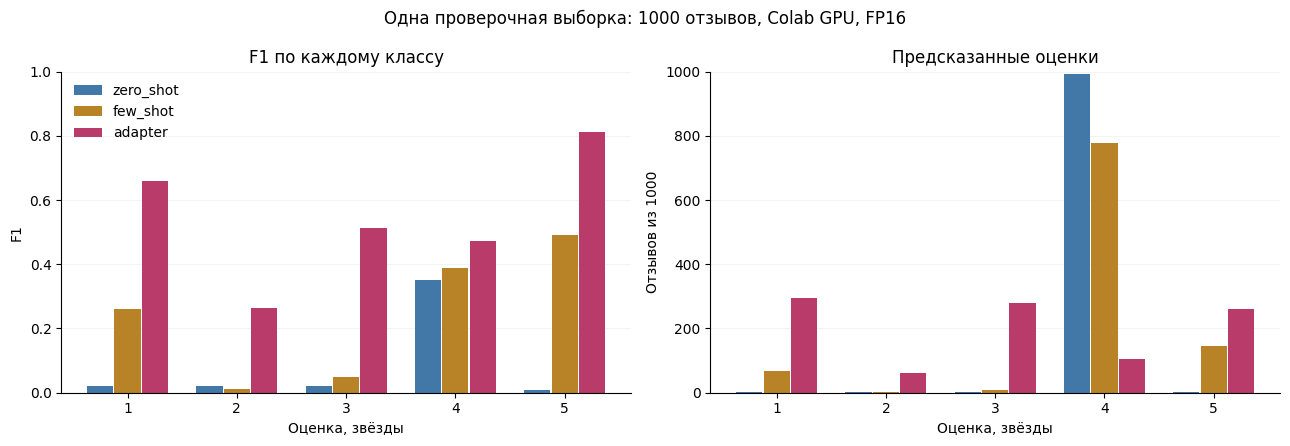

Первые три отзыва:


,idx,label,zero_shot,few_shot,adapter
0,0,3,4,4,1
1,1,4,4,4,4
2,2,2,4,4,2


In [10]:
import matplotlib.pyplot as plt
import numpy as np
colors = ["#4178a8", "#b78326", "#b83b69"]
x = np.arange(5)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for j, mode in enumerate(MODES):
    result = metrics["modes"][mode]
    positions = x + (j - 1) * 0.25
    axes[0].bar(positions, [result["f1_per_class"][str(c)] for c in range(1, 6)],
                width=0.24, label=mode, color=colors[j])
    axes[1].bar(positions, [result["prediction_counts"][str(c)] for c in range(1, 6)],
                width=0.24, label=mode, color=colors[j])
for ax in axes:
    ax.set_xticks(x, [1, 2, 3, 4, 5])
    ax.set_xlabel("Оценка, звёзды")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
axes[0].set(title="F1 по каждому классу", ylabel="F1", ylim=(0, 1))
axes[1].set(title="Предсказанные оценки", ylabel="Отзывов из 1000", ylim=(0, 1000))
axes[0].legend(frameon=False)
fig.suptitle("Одна проверочная выборка: 1000 отзывов, Colab GPU, FP16")
fig.tight_layout()
fig.savefig(OUT / "comparison.png", dpi=150)
plt.show()
rows = list(csv.DictReader((OUT / "predictions.csv").open()))
assert len(rows) == 1000
print("Первые три отзыва:")
display(pd.DataFrame(rows[:3])[["idx", "label", "zero_shot", "few_shot", "adapter"]])

## 7. Забираем результаты

Архив содержит все 3000 ответов, метрики, график и исходный код прогона. Скачайте также этот ноутбук через Файл → Скачать → Скачать IPYNB, чтобы сохранить выводы. Адаптер не переобучался и остаётся прежним.

In [11]:
archive = WORK / "lab04-colab-evaluation-results.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for path in sorted(OUT.glob("*")):
        if path.is_file():
            z.write(path, "evaluation/" + path.name)
    for name in ["run.py", "data.py", "prompting.py", "evaluation.py"]:
        z.write(WORK / "lab04" / name, "source/" + name)
print("Архив результатов, байт:", archive.stat().st_size)
files.download(str(archive))

Архив результатов, байт: 269781


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>